# 01 - Exploratory data analysis

Dataset: `data/processed/dataset.csv` (cleaned Khmer news articles, label = topic).
All numbers below are computed by `src/eda.py`; the *Findings* cells were written on 2026-11-24 from those numbers
and must be re-checked if the dataset changes.

In [1]:
import os
os.chdir("..")  # run from the project root so relative paths work
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_colwidth", 120)
from src import eda
eda.main()

EDA done: 3,138 articles. See reports/eda_summary.md, reports/figures/, reports/eda/


## 1. Class balance and sources

,CEN,DAP News,Kampuchea Thmey,total,largest_source_share
label,,,,,
politics,241,373,0,614,61%
economy,242,304,0,546,56%
technology,243,313,0,556,56%
sports,0,381,161,542,70%
society_health,297,164,0,461,64%
entertainment,296,123,0,419,71%


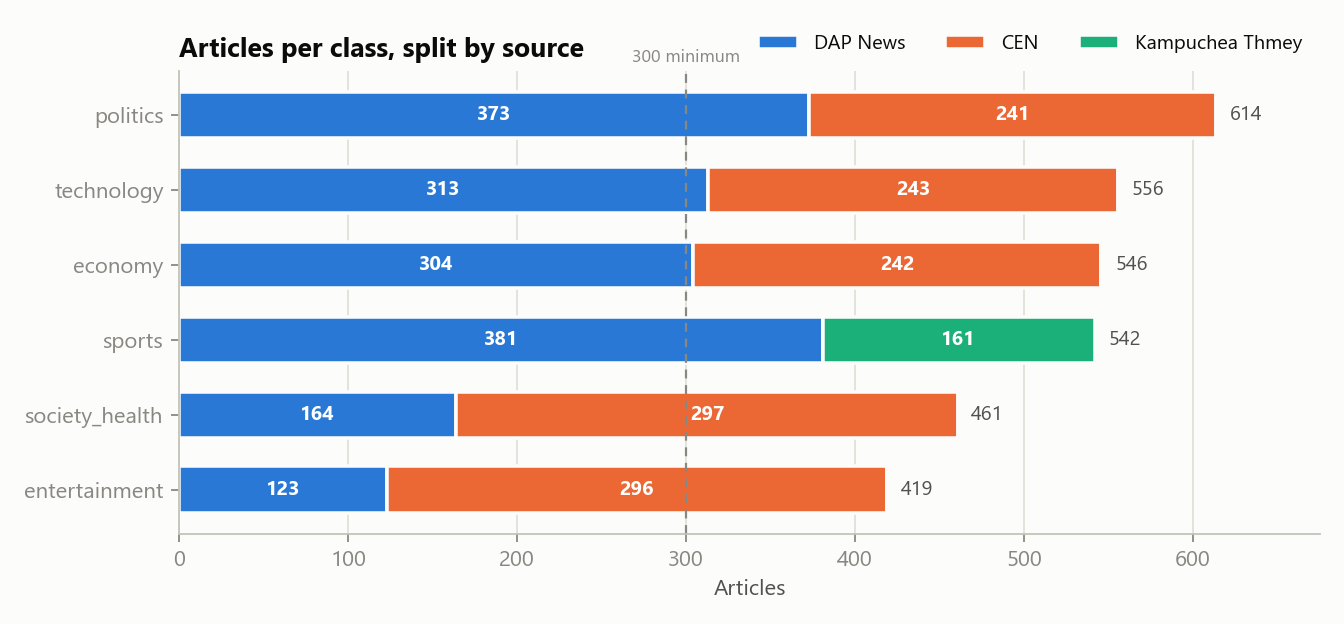

In [2]:
display(pd.read_csv("reports/eda/class_by_source.csv", index_col=0))
display(Image("reports/figures/fig_class_balance.png"))

**Findings.** Every class has between 419 and 614 articles (all above the 300 minimum) and two sources, but the mix is uneven:
entertainment is 71% CEN, society_health 64% CEN, sports 70% DAP. Sports is the only class whose second source (Kampuchea Thmey) is small (161).

## 2. Text length

,count,mean,5%,50%,95%,max
label,,,,,,
politics,614,1954,411,1650,4350,10275
economy,546,2358,738,2002,5359,10859
technology,556,2008,682,1482,4768,21338
sports,542,1544,502,1344,3607,6365
society_health,461,2236,661,2196,3961,13386
entertainment,419,1910,623,1679,4141,5818


,count,mean,5%,50%,95%,max
src,,,,,,
CEN,1319,2197,754,1968,4347,10275
DAP News,1658,1869,467,1473,4406,21338
Kampuchea Thmey,161,1709,895,1530,3256,4668


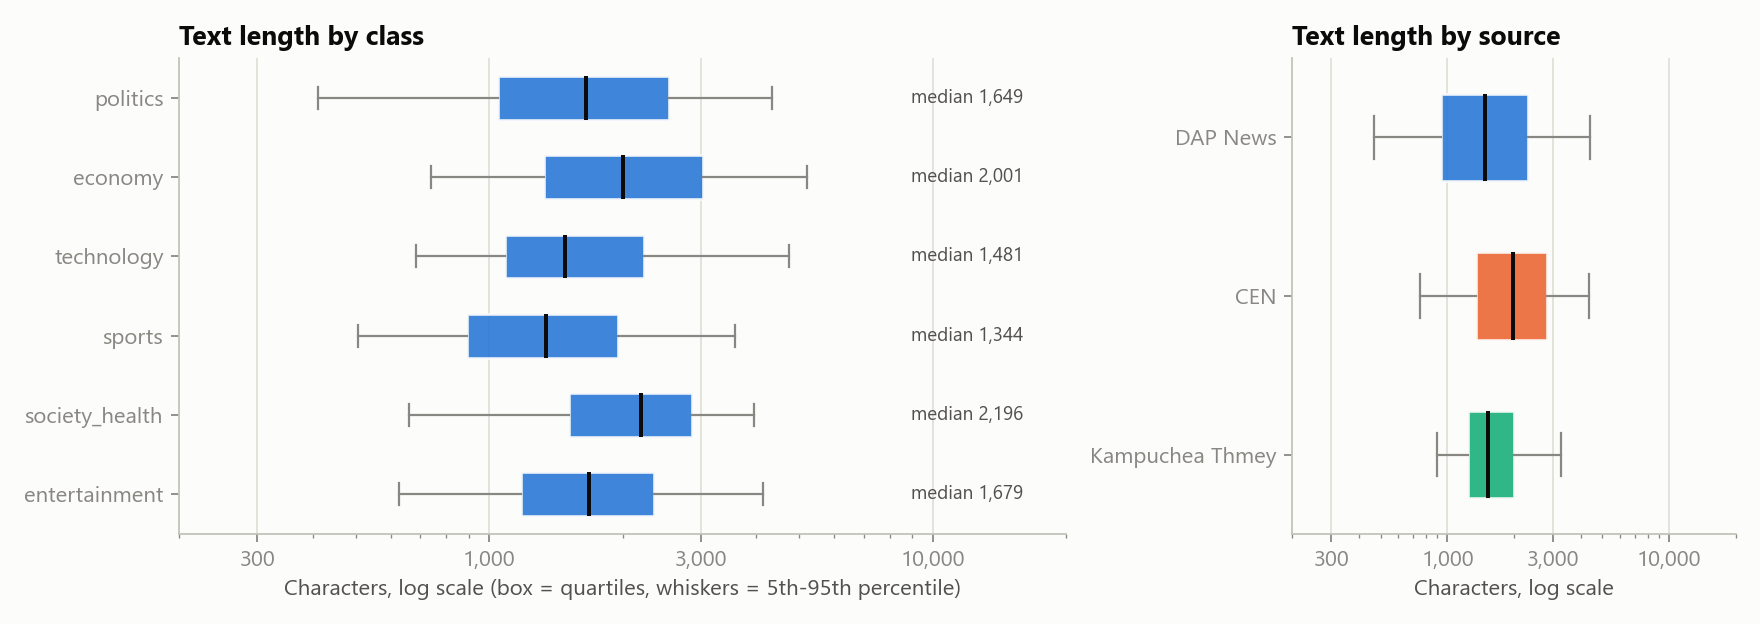

In [3]:
display(pd.read_csv("reports/eda/length_by_class.csv", index_col=0))
display(pd.read_csv("reports/eda/length_by_source.csv", index_col=0))
display(Image("reports/figures/fig_length.png"))

**Findings.** Median length is 1,344 (sports) to 2,196 (society_health) characters; the 95th percentile is at most 5,359, but one technology article has 21,338.
Models should cap the text length (for example the first 5,000 characters) so a few very long articles do not dominate. Length differs by class
(sports shortest, economy and society_health longest), so length itself carries some label signal; it is not a defect, but be aware of it.

## 3. Khmer vs. English content

,median_khmer_share,articles_below_0_80,median_latin_share
label,,,
politics,0.940,0,0.000
economy,0.930,6,0.013
technology,0.917,29,0.032
sports,0.884,56,0.051
society_health,0.946,3,0.000
entertainment,0.930,8,0.012


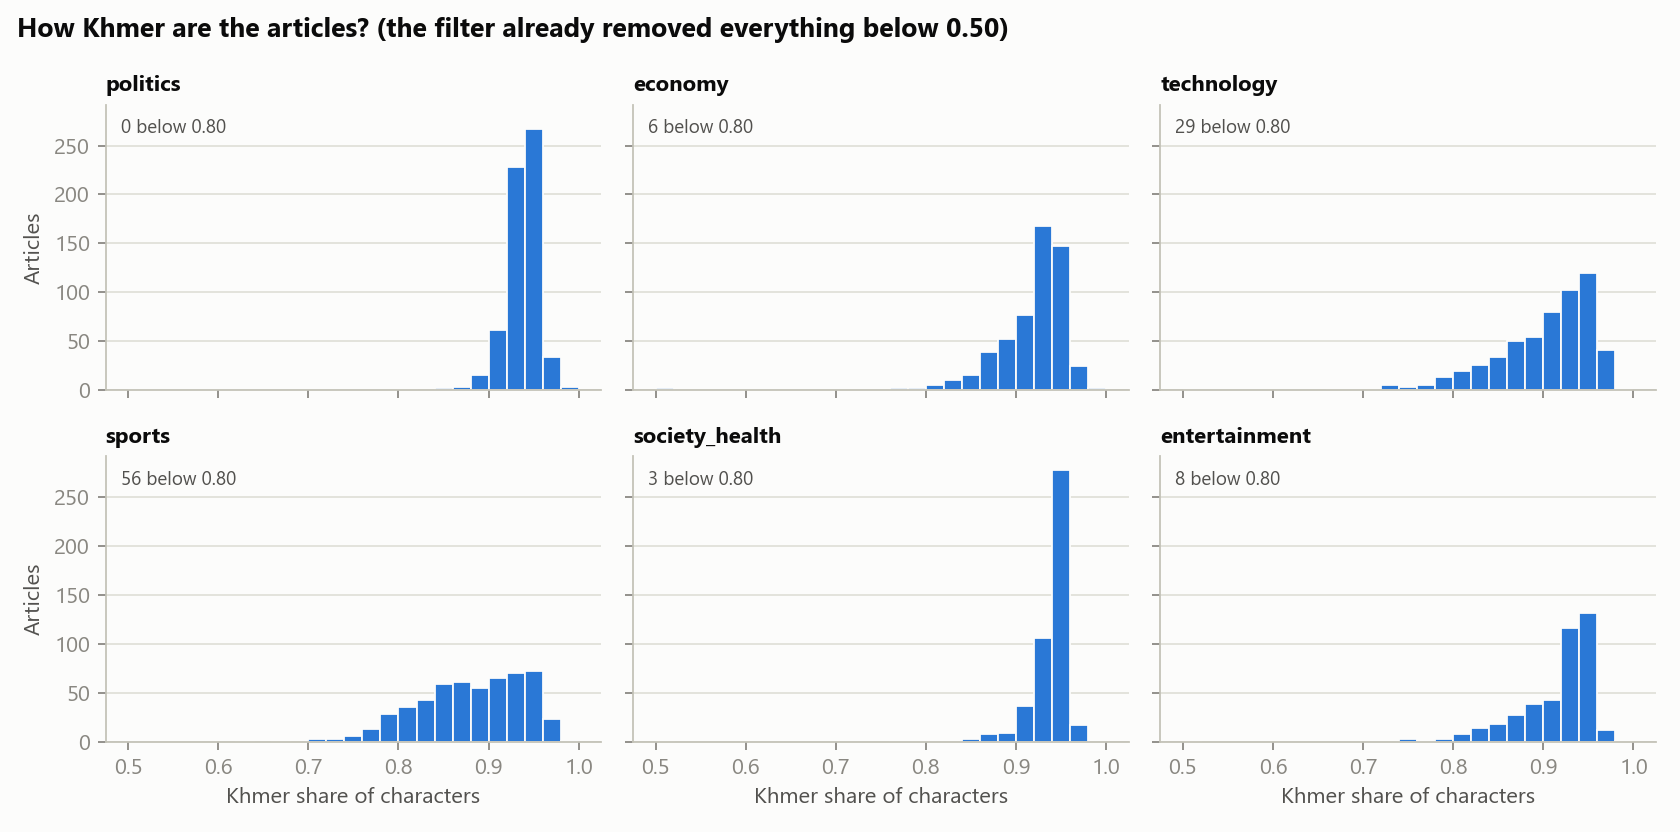

In [4]:
display(pd.read_csv("reports/eda/language_by_class.csv", index_col=0))
display(Image("reports/figures/fig_khmer_share.png"))

**Findings.** The articles are overwhelmingly Khmer (median share 0.88 to 0.95). 102 articles (3.3%) are below 0.80, mostly in sports (56) and technology (29):
team, player and brand names in Latin letters. This is real code-switching and is kept on purpose; character n-grams handle it without special treatment.

## 4. Time coverage

,2019,2020,2021,2022,2023,2024,2025,2026
label,,,,,,,,
politics,0,0,0,97,229,26,12,250
economy,0,32,59,78,35,57,20,265
technology,4,50,144,112,81,71,61,33
sports,0,0,0,52,74,77,30,309
society_health,67,16,11,268,59,33,7,0
entertainment,21,25,8,18,160,90,68,29


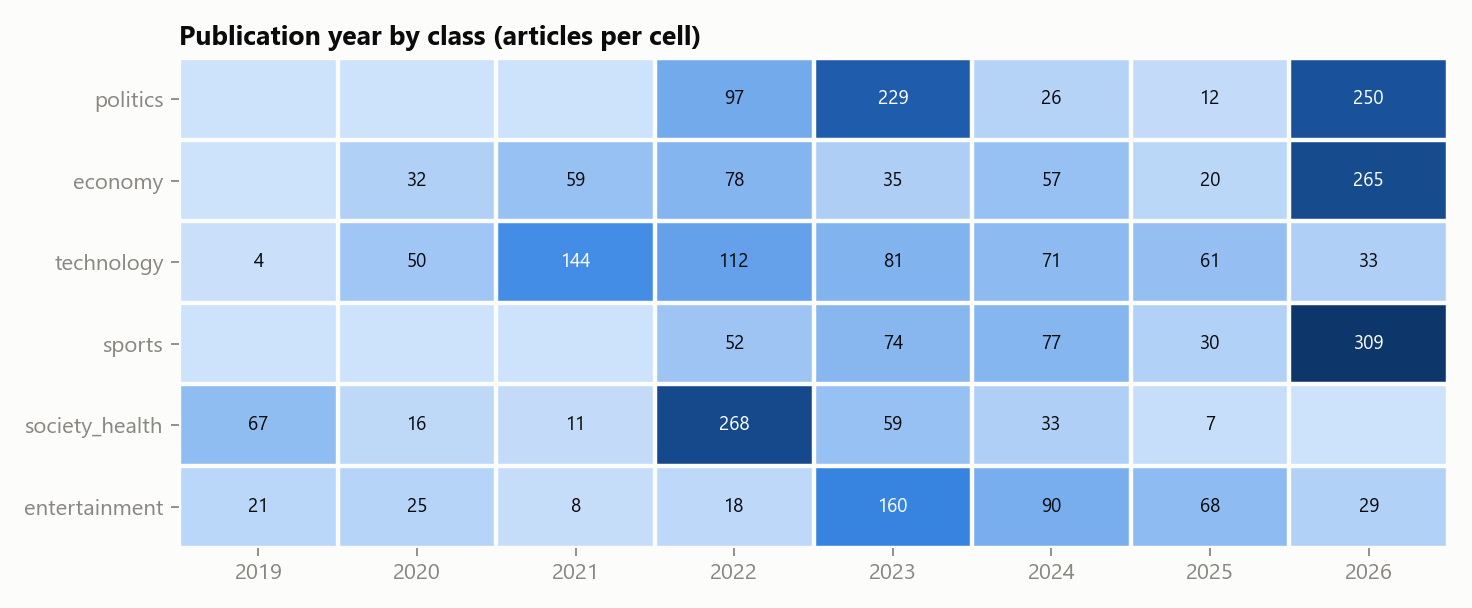

In [5]:
display(pd.read_csv("reports/eda/year_by_class.csv", index_col=0))
display(Image("reports/figures/fig_year_heatmap.png"))

**Findings - a time confound.** The classes do not cover the same period. Sports (57%), economy (49%) and politics (41%) are mostly 2026 news,
whereas society_health has **no** 2026 articles (most are from 2022) and technology (6%) and entertainment (7%) are mostly older.
Year strings such as 2026 (written in Khmer digits) were among the strongest features separating sources, so a model could partly learn
"2026 means sports or politics". Check this in error analysis, and consider removing or masking years in the model-time preprocessing.

## 5. Characters and distinctive n-grams

In [6]:
display(pd.read_csv("reports/eda/top_khmer_characters.csv").head(15))
display(pd.read_csv("reports/eda/distinctive_4grams_by_class.csv"))

,char,codepoint,name,per_1000_chars
0,្,U+17D2,Sign Coeng,81.0
1,ា,U+17B6,Vowel Sign Aa,77.9
2,ន,U+1793,Letter No,58.5
3,រ,U+179A,Letter Ro,52.5
4,ក,U+1780,Letter Ka,45.8
5,ប,U+1794,Letter Ba,37.9
6,ម,U+1798,Letter Mo,33.4
7,ស,U+179F,Letter Sa,32.1
8,ង,U+1784,Letter Ngo,30.3
9,ត,U+178F,Letter Ta,29.6


,class,top distinctive 4-grams (articles containing it)
0,politics,"្សភ្ (62), ជ.ប) (46), ង្ស៊ (40), លឹកឆ (38), ក្សភ (63), ងទៀន (61), .ជ.ប (60), នគណប (108), រគណប (48), យគណប (68)"
1,economy,"ក.អ. (26), (ក.អ (25), ផរណា (23), ិផរណ (23), តិផរ (23), អតិផ (23), .អ.ក (27), អ.ក. (23), ប់ហិ (21), ាសអន (25)"
2,technology,"ជនខិ (57), នខិល (57), ខិលខ (58), ិលខូ (58), ថ្មភ (33), ្មភក (31), មភក់ (31), បដិម (37), ដិមា (37), េខសម (39)"
3,sports,"ងពូល (88), ុងពូ (81), នះនេ (39), គទីព (38), នៅកី (95), ទីទី (93), មបាល (80), ៅកីឡ (99), ្ទុដ (27), លិបប (26)"
4,society_health,"ឹងឯង (50), ៀនយល (45), ចូរក (44), ុញថប (41), ធុញថ (41), ញថប់ (41), ធឈាម (39), ាធឈា (33), ពាធឈ (33), ៉ាំទ (32)"
5,entertainment,"េងអ៊ (42), យមលេ (42), ហួសច (43), ួសចិ (43), ិយមល (42), នាងគ (20), ិយមិ (29), សចិត (44), នាង។ (35), គមសិ (26)"


**Findings.** The most frequent characters are the Khmer subscript sign (coeng), the vowel sign aa and the consonants no, ro and ka. The distinctive 4-grams per class look topical
rather than like site artifacts. In the author's reading: politics (the word for political party, the abbreviation of the election committee), economy (the word for inflation),
sports (the words for sport and ball/football), entertainment (the pronoun for "she", a word meaning "astonished"), society_health (the word for blood, everyday-life wording).
These readings come from a non-expert pass and should be confirmed by a Khmer reader before they go into the report. The overall picture is encouraging: a bag-of-character-n-grams model has topical signal to learn.

## 6. Can the source be recognised from the text?

,class,source_a,source_b,articles,balanced_accuracy
0,politics,CEN,DAP News,614,0.950
1,economy,CEN,DAP News,546,0.905
2,technology,CEN,DAP News,556,0.886
3,sports,DAP News,Kampuchea Thmey,542,0.944
4,society_health,CEN,DAP News,461,0.987
5,entertainment,CEN,DAP News,419,0.834


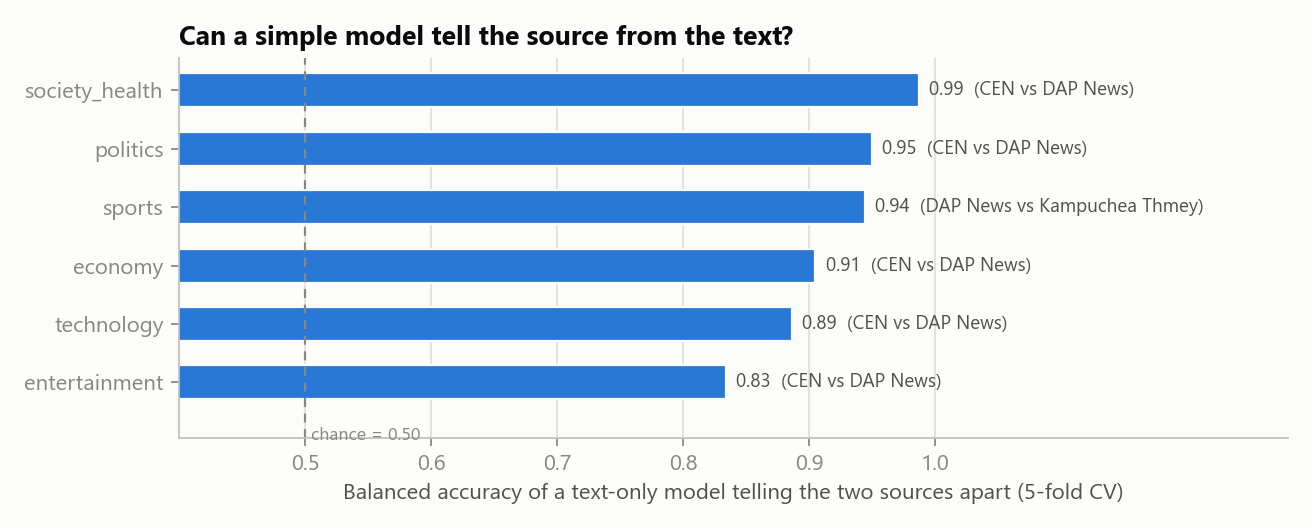

In [7]:
display(pd.read_csv("reports/eda/source_predictability.csv"))
display(Image("reports/figures/fig_source_predictability.png"))

**Findings - shortcut risk.** A plain TF-IDF logistic regression tells the two sources of a class apart with 0.83 (entertainment) to 0.99 (society_health) balanced accuracy.
Because class and source are correlated (Cramer's V = 0.45: entertainment and society_health are mostly CEN, sports and politics mostly DAP), a classifier can use source style as a shortcut to the label.

We tested whether this is just typesetting: mapping the spelling variant of one Khmer word, removing spaces before full stops, removing datelines and replacing numbers
changed the mean source accuracy only from 0.918 to 0.908. So the sources differ in real content (periods covered, editorial focus), and simple normalisation does not remove it.

**What to do instead (evaluation design):**
1. Stratify the train/validation/test split by class *and* source, so every split has the same source mix.
2. Report scores per source as well as overall.
3. Add a cross-source experiment (train on DAP only, test on CEN) to measure how much of the accuracy is topic and how much is source style.
4. Keep the source out of the model inputs (never use the source column as a feature).

## 7. Summary of recommendations
- Dataset is usable as is: 3,138 articles, six classes, every class above 400 with two sources.
- Cap text length (about 5,000 characters) for the models.
- Split by class x source with a fixed seed; report overall and per-source metrics; run a cross-source test.
- Treat the time confound (society_health is old, sports and politics are recent) as a known limitation and look at it in error analysis.
- Label spot-check: `reports/label_spotcheck.csv` has 110 random articles (25 from society_health, the least certain class) ready to fill in.